# EDA - Manifiesto Clinico Unificado

A diferencia de los otros 4 notebooks de esta carpeta (que exploran el **dato crudo** de cada fuente por separado), este explora `datasets/manifest/rop_unified_manifest.parquet` - el resultado **ya unificado** de `system/dataset_build/partition/build_manifest.py` (RIDIRP + FARFUM + ROP-VL, cada uno ya pasado por su `clean_<dataset>.py`).

**Objetivo:** entender el desbalance de clases y los patrones de nulos a nivel del **pool combinado** (no por dataset aislado) - es el insumo directo para decidir la estrategia de estratificacion del script de Group K-Fold (pendiente, ver `system/dataset_build/README.md`).

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent.parent  # system/eda/ -> ROP_paper/
MANIFEST_PATH = ROOT / "datasets" / "manifest" / "rop_unified_manifest.parquet"

plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 20)

df = pd.read_parquet(MANIFEST_PATH)
print("filas (imagenes):", len(df))
print("bags:", df["bag_id"].nunique())
print("pacientes:", df["patient_id_global"].nunique())
print()
print(df["dataset_origen"].value_counts())
df.head()

filas (imagenes): 7881
bags: 1964
pacientes: 1182

dataset_origen
RIDIRP    4709
ROP-VL    1639
FARFUM    1533
Name: count, dtype: int64


,sample_id,bag_id,dataset_origen,patient_id_global,image_path,sexo,GA,BW,PMA,pma_available,stage,plus,ap_rop,split,fold
0,RIDIRP_028_S01_1,RIDIRP_028_S01,RIDIRP,RIDIRP_028,RIDIRP/images_stack_without_captions/028_F_GA3...,F,32.0,1760.0,33.142857,True,0.0,Normal,False,None,None
1,RIDIRP_028_S01_2,RIDIRP_028_S01,RIDIRP,RIDIRP_028,RIDIRP/images_stack_without_captions/028_F_GA3...,F,32.0,1760.0,33.142857,True,0.0,Normal,False,None,None
2,RIDIRP_028_S01_3,RIDIRP_028_S01,RIDIRP,RIDIRP_028,RIDIRP/images_stack_without_captions/028_F_GA3...,F,32.0,1760.0,33.142857,True,0.0,Normal,False,None,None
3,RIDIRP_028_S01_4,RIDIRP_028_S01,RIDIRP,RIDIRP_028,RIDIRP/images_stack_without_captions/028_F_GA3...,F,32.0,1760.0,33.142857,True,0.0,Normal,False,None,None
4,RIDIRP_028_S01_5,RIDIRP_028_S01,RIDIRP,RIDIRP_028,RIDIRP/images_stack_without_captions/028_F_GA3...,F,32.0,1760.0,33.142857,True,0.0,Normal,False,None,None


## Distribucion de `stage` - pooled y por dataset de origen

Las 3 fuentes aportan `stage` con distinta cobertura y distinta forma (RIDIRP/FARFUM sesgados a estadios bajos, ROP-VL mejor balanceado e incluye los casos raros 4/5). Vemos primero el pool combinado (lo que realmente va a ver el modelo en Fase 2/3), despues el desglose por fuente para no perder esa diferencia.

--- stage por imagen (pooled) ---
stage
0.0    3618
1.0     509
2.0    1591
3.0    1078
4.0      61
5.0      34
NaN     990
Name: count, dtype: int64

cobertura: 87.4%

--- stage por bag (pooled) ---
stage
0.0    876
1.0    213
2.0    359
3.0    261
4.0     54
5.0     30
NaN    171
Name: count, dtype: int64

cobertura: 91.3%


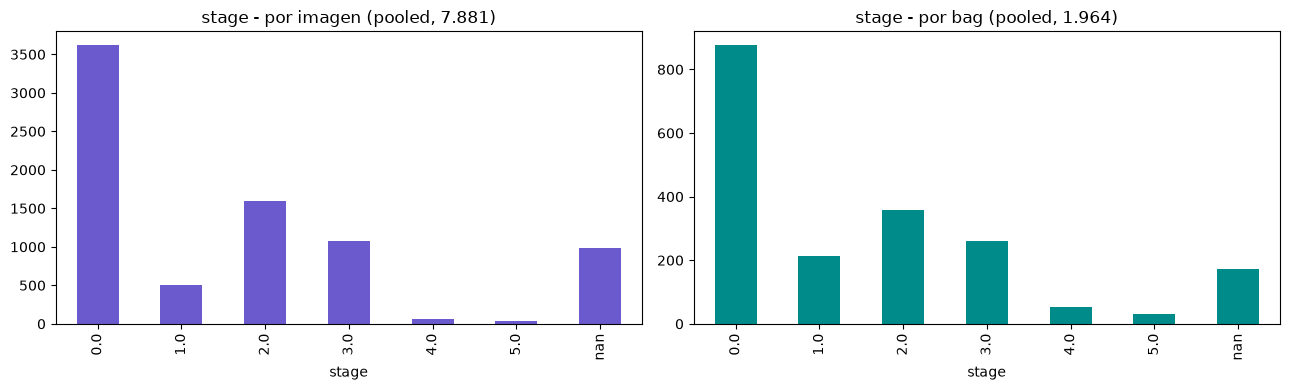

In [2]:
bags = df.drop_duplicates("bag_id")

print("--- stage por imagen (pooled) ---")
print(df["stage"].value_counts(dropna=False).sort_index())
print(f"\ncobertura: {100*df['stage'].notna().mean():.1f}%")

print("\n--- stage por bag (pooled) ---")
print(bags["stage"].value_counts(dropna=False).sort_index())
print(f"\ncobertura: {100*bags['stage'].notna().mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["stage"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set_title("stage - por imagen (pooled, 7.881)")
bags["stage"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[1], color="darkcyan")
axes[1].set_title("stage - por bag (pooled, 1.964)")
plt.tight_layout()
plt.show()

stage           0.0  1.0  2.0  3.0  4.0  5.0  NaN
dataset_origen                                   
FARFUM            0    4   33   29    0    0    2
RIDIRP          283   16   28    4    0    0   43
ROP-VL          593  193  298  228   54   30  126

% fila (ignora NaN como categoria para que sea mas legible):
stage            0.0   1.0   2.0   3.0  4.0  5.0
dataset_origen                                  
FARFUM           0.0   6.1  50.0  43.9  0.0  0.0
RIDIRP          85.5   4.8   8.5   1.2  0.0  0.0
ROP-VL          42.5  13.8  21.3  16.3  3.9  2.1


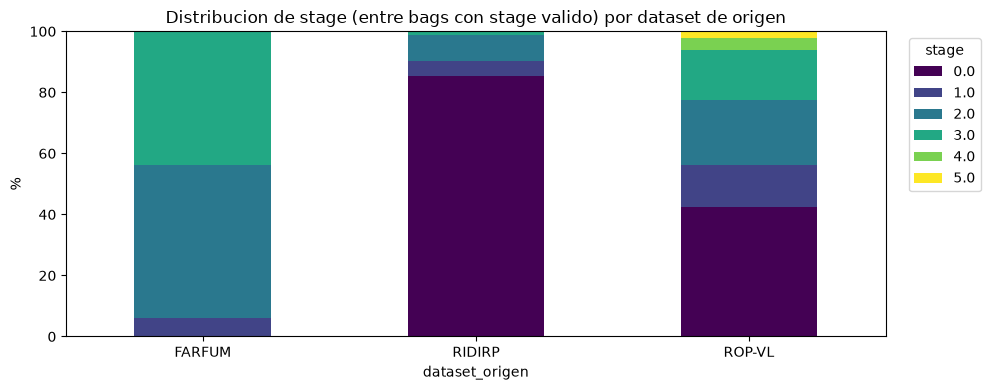

In [3]:
# stage por bag, desglosado por dataset de origen (crosstab normalizado por fila)
stage_by_source = pd.crosstab(bags["dataset_origen"], bags["stage"], dropna=False)
print(stage_by_source)
print()
print("% fila (ignora NaN como categoria para que sea mas legible):")
stage_pct = pd.crosstab(bags["dataset_origen"], bags["stage"], normalize="index") * 100
print(stage_pct.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
stage_pct.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_title("Distribucion de stage (entre bags con stage valido) por dataset de origen")
ax.set_ylabel("%")
ax.legend(title="stage", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Distribucion de `plus` - pooled, por imagen y por PACIENTE real

El conteo por imagen puede exagerar la diversidad real (un paciente con muchas visitas/fotos infla el conteo sin aportar diversidad - ya lo vimos con RIDIRP en su propio EDA). Repetimos el analisis a nivel de paciente real aqui, con codigo directo sobre el manifiesto ya unificado (antes se hacia cruzando `clean_ridirp.parquet` con el manifiesto por separado - ya no hace falta, RIDIRP ya esta adentro).

--- plus por imagen (pooled) ---
plus
Normal      4844
NaN         1639
Plus         917
Pre-Plus     481
Name: count, dtype: int64

--- plus por PACIENTE real (el mas severo visto en cualquiera de sus imagenes/visitas) ---
plus            Normal  Plus  Pre-Plus  NaN
dataset_origen                             
FARFUM              33    15        20    0
RIDIRP             147     3         0    0
ROP-VL               0     0         0  964

Total pacientes con Plus o Pre-Plus (cualquier fuente): 38


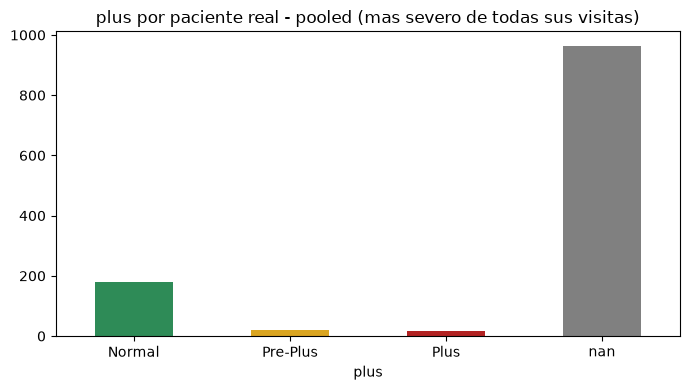

In [4]:
print("--- plus por imagen (pooled) ---")
print(df["plus"].value_counts(dropna=False))

PLUS_SEVERITY = {"Normal": 0, "Pre-Plus": 1, "Plus": 2}
patient_plus = df.groupby("patient_id_global")["plus"].apply(
    lambda s: max(s.dropna(), key=lambda v: PLUS_SEVERITY[v]) if s.notna().any() else None
)
patient_origen = df.drop_duplicates("patient_id_global").set_index("patient_id_global")["dataset_origen"]

print("\n--- plus por PACIENTE real (el mas severo visto en cualquiera de sus imagenes/visitas) ---")
tabla = pd.crosstab(patient_origen, patient_plus, dropna=False)
print(tabla)
print("\nTotal pacientes con Plus o Pre-Plus (cualquier fuente):", int(patient_plus.isin(["Plus", "Pre-Plus"]).sum()))

fig, ax = plt.subplots(figsize=(7, 4))
patient_plus.value_counts(dropna=False).reindex(["Normal", "Pre-Plus", "Plus", None]).plot(kind="bar", ax=ax, color=["seagreen", "goldenrod", "firebrick", "gray"])
ax.set_title("plus por paciente real - pooled (mas severo de todas sus visitas)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Distribucion de `ap_rop` - pooled (recordando que `None` != `False`)

`ap_rop` es nullable de 3 valores: `True` (confirmado), `False` (confirmado negativo, imagen con estadio numerico valido) y `None` (enmascarado - no se puede afirmar nada, no cuenta como negativo). Verificamos la proporcion real de positivos **entre las filas con dato** (ignorando las enmascaradas), que es lo relevante para pensar en el peso de clase de este cabezal.

--- ap_rop por imagen (pooled) ---
ap_rop
False    5335
None     1912
True      634
Name: count, dtype: int64

entre filas CON dato (5969 de 7881):
  True:  634 (10.6%)
  False: 5335 (89.4%)

--- por dataset de origen ---
dataset_origen  ap_rop
FARFUM          NaN       1533
RIDIRP          False     3860
                True       470
                NaN        379
ROP-VL          False     1475
                True       164
Name: count, dtype: int64

pacientes con AP-ROP confirmado alguna vez: 102 de 1182


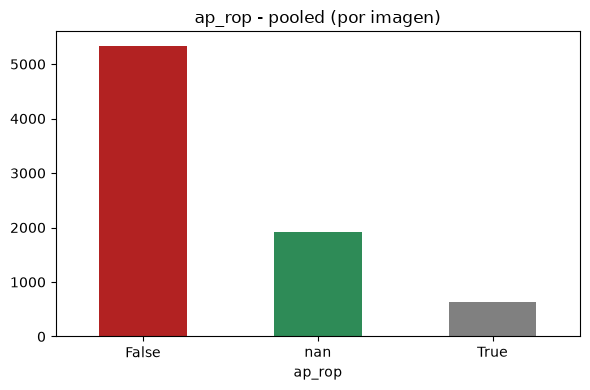

In [5]:
print("--- ap_rop por imagen (pooled) ---")
print(df["ap_rop"].value_counts(dropna=False))

with_data = df[df["ap_rop"].notna()]
print(f"\nentre filas CON dato ({len(with_data)} de {len(df)}):")
print(f"  True:  {int((with_data['ap_rop'] == True).sum())} ({100*(with_data['ap_rop'] == True).mean():.1f}%)")
print(f"  False: {int((with_data['ap_rop'] == False).sum())} ({100*(with_data['ap_rop'] == False).mean():.1f}%)")

print("\n--- por dataset de origen ---")
print(df.groupby("dataset_origen")["ap_rop"].value_counts(dropna=False))

# pacientes con AP-ROP confirmado alguna vez (cualquiera de sus imagenes/visitas)
patient_ap_rop = df.groupby("patient_id_global")["ap_rop"].apply(lambda s: bool((s == True).any()))
print(f"\npacientes con AP-ROP confirmado alguna vez: {int(patient_ap_rop.sum())} de {df['patient_id_global'].nunique()}")

fig, ax = plt.subplots(figsize=(6, 4))
df["ap_rop"].value_counts(dropna=False).rename({True: "True", False: "False"}).plot(kind="bar", ax=ax, color=["firebrick", "seagreen", "gray"])
ax.set_title("ap_rop - pooled (por imagen)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Patron de nulos cruzado: ¿cuantas de las 3 tareas tiene cada bag?

Relevante para la perdida multitarea enmascarada: un bag puede aportar gradiente a 0, 1, 2 o las 3 tareas a la vez. Verificamos la combinacion real (no solo la cobertura de cada tarea por separado, que ya vimos arriba).

--- cuantas tareas (de 3) tiene cada bag, pooled ---
n_tareas
1     155
2    1478
3     331
Name: count, dtype: int64

bags con 0 tareas (no deberian existir - sin gradiente para nada): 0

--- combinaciones exactas de que tareas tiene cada bag ---
 has_stage  has_plus  has_ap_rop  n_bags
     False     False        True     126
     False      True       False      29
     False      True        True      16
      True     False        True    1396
      True      True       False      66
      True      True        True     331

--- por dataset de origen ---
n_tareas          1     2    3
dataset_origen                
FARFUM            2    66    0
RIDIRP           27    16  331
ROP-VL          126  1396    0


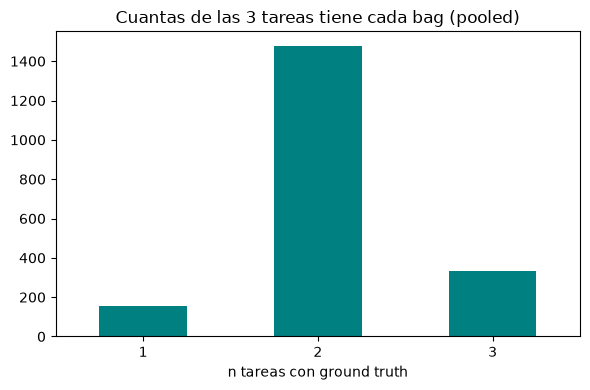

In [6]:
bags = df.drop_duplicates("bag_id").copy()
bags["has_stage"] = bags["stage"].notna()
bags["has_plus"] = bags["plus"].notna()
bags["has_ap_rop"] = bags["ap_rop"].notna()
bags["n_tareas"] = bags[["has_stage", "has_plus", "has_ap_rop"]].sum(axis=1)

print("--- cuantas tareas (de 3) tiene cada bag, pooled ---")
print(bags["n_tareas"].value_counts().sort_index())
print(f"\nbags con 0 tareas (no deberian existir - sin gradiente para nada): {int((bags['n_tareas']==0).sum())}")

print("\n--- combinaciones exactas de que tareas tiene cada bag ---")
combo = bags.groupby(["has_stage", "has_plus", "has_ap_rop"]).size().rename("n_bags").reset_index()
print(combo.to_string(index=False))

print("\n--- por dataset de origen ---")
print(pd.crosstab(bags["dataset_origen"], bags["n_tareas"]))

fig, ax = plt.subplots(figsize=(6, 4))
bags["n_tareas"].value_counts().sort_index().plot(kind="bar", ax=ax, color="teal")
ax.set_title("Cuantas de las 3 tareas tiene cada bag (pooled)")
ax.set_xlabel("n tareas con ground truth")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Bags e imagenes por paciente (pool combinado) - tamano de los grupos del futuro K-Fold

El Group K-Fold agrupa por `patient_id_global` - un paciente con muchos bags/imagenes "pesa" mas en su fold. Vemos la distribucion real para detectar pacientes atipicamente grandes (como RIDIRP_043, ya visto en su propio EDA) a nivel del pool completo.

--- bags por paciente (pooled) ---
count    1182.000000
mean        1.661591
std         1.014975
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        16.000000
dtype: float64

top 10 pacientes con mas bags:
patient_id_global
RIDIRP_043    16
RIDIRP_139    11
RIDIRP_031     9
RIDIRP_138     9
RIDIRP_052     8
RIDIRP_084     6
RIDIRP_066     6
RIDIRP_112     5
RIDIRP_098     5
RIDIRP_115     5
dtype: int64

--- imagenes por paciente (pooled) ---
count    1182.000000
mean        6.667513
std        19.674754
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max       470.000000
dtype: float64


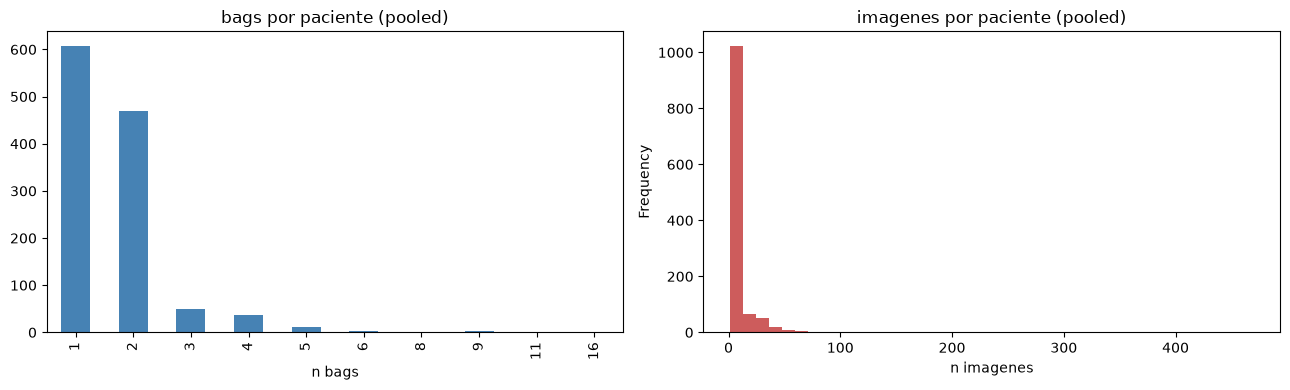

In [7]:
bags_por_paciente = df.drop_duplicates("bag_id").groupby("patient_id_global").size()
imgs_por_paciente = df.groupby("patient_id_global").size()

print("--- bags por paciente (pooled) ---")
print(bags_por_paciente.describe())
print("\ntop 10 pacientes con mas bags:")
print(bags_por_paciente.sort_values(ascending=False).head(10))

print("\n--- imagenes por paciente (pooled) ---")
print(imgs_por_paciente.describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bags_por_paciente.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("bags por paciente (pooled)")
axes[0].set_xlabel("n bags")
imgs_por_paciente.plot(kind="hist", bins=40, ax=axes[1], color="indianred")
axes[1].set_title("imagenes por paciente (pooled)")
axes[1].set_xlabel("n imagenes")
plt.tight_layout()
plt.show()

## GA / BW pooled, por dataset de origen

Rapido chequeo de si las 3 fuentes cubren poblaciones de prematuridad comparables (relevante para que el vector clinico GA+BW+sexo generalice entre fuentes en Fase 2).

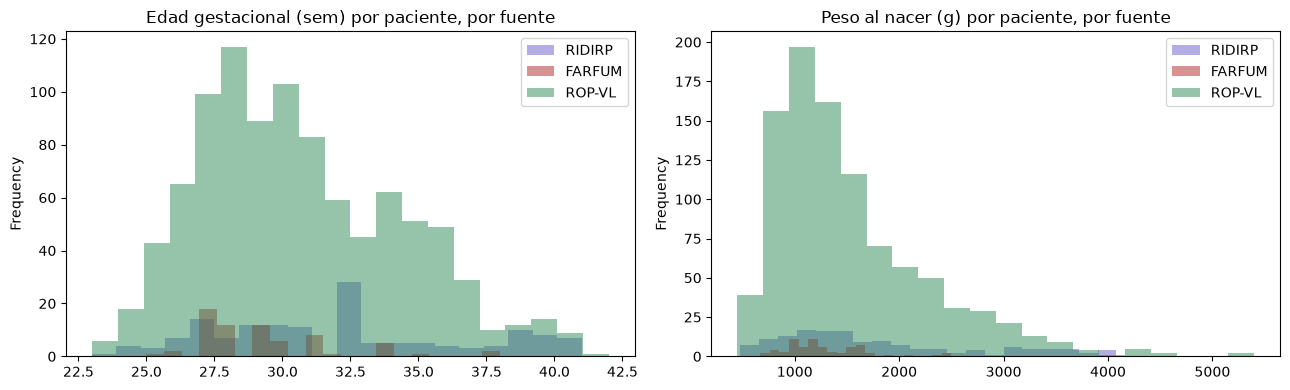

dataset_origen       FARFUM       RIDIRP       ROP-VL
GA count          68.000000   150.000000   964.000000
   mean           29.235294    32.060000    30.549793
   std             2.688381     4.696464     3.898320
   min            25.000000    23.000000    23.000000
   25%            27.000000    29.000000    28.000000
   50%            29.000000    32.000000    30.000000
   75%            30.250000    35.000000    33.000000
   max            38.000000    41.000000    42.000000
BW count          68.000000   150.000000   964.000000
   mean         1288.308824  1791.966667  1518.731328
   std           389.612906   942.597599   745.132067
   min           670.000000   480.000000   450.000000
   25%          1000.000000  1122.500000   990.000000
   50%          1200.000000  1490.000000  1300.000000
   75%          1530.000000  2317.500000  1850.000000
   max          2500.000000  4080.000000  5400.000000


In [8]:
patient_level = df.drop_duplicates("patient_id_global")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for origen, color in zip(["RIDIRP", "FARFUM", "ROP-VL"], ["slateblue", "firebrick", "seagreen"]):
    sub = patient_level[patient_level["dataset_origen"] == origen]
    sub["GA"].plot(kind="hist", bins=20, ax=axes[0], alpha=0.5, label=origen, color=color)
    sub["BW"].plot(kind="hist", bins=20, ax=axes[1], alpha=0.5, label=origen, color=color)
axes[0].set_title("Edad gestacional (sem) por paciente, por fuente")
axes[0].legend()
axes[1].set_title("Peso al nacer (g) por paciente, por fuente")
axes[1].legend()
plt.tight_layout()
plt.show()

print(patient_level.groupby("dataset_origen")[["GA", "BW"]].describe().T)

## Resumen de hallazgos - manifiesto unificado

**Tamaño del pool:** 7.881 imágenes, 1.964 bags, 1.182 pacientes (RIDIRP 150, FARFUM 68, ROP-VL 964).

**`stage` (87.4% cobertura por imagen, 91.3% por bag) — las 3 fuentes tienen formas muy distintas, no solo volumen distinto:**
- RIDIRP: 85.5% de sus bags con stage válido son Estadio 0 — casi no aporta estadios altos.
- FARFUM: **0% Estadio 0** (nunca "normal" en sus bags con stage válido) — concentrado en 2-3 (50.0%/43.9%).
- ROP-VL: la única fuente con Estadio 4/5 (3.9%/2.1%, 84 bags) y la más balanceada en general.
- Implicación directa para el K-Fold: estratificar solo por `dataset_origen` no alcanza — folds que por azar concentren ROP-VL se llevarían casi todos los casos 4/5.

**`plus` — problema de diversidad de pacientes, no solo de frecuencia:** solo **38 pacientes reales** (de 218 que SÍ tienen esta etiqueta, RIDIRP+FARFUM) tienen alguna vez Plus/Pre-Plus — RIDIRP aporta solo 3 (dominados por el paciente 043), FARFUM aporta 35 reales. ROP-VL no participa de esta tarea (964 pacientes sin dato). Con un grupo positivo tan chico, un Group K-Fold ingenuo podría dejar folds enteros sin ningún caso Plus.

**`ap_rop` — 10.6% positivo entre filas con dato (634 True / 5.335 False), 24.3% enmascarado.** 102 pacientes (de 1.182) tienen AP-ROP confirmado alguna vez — pero la combinación de nulos (`stage=NaN, plus=valido, ap_rop=True`, 16 bags) es **el paciente `RIDIRP_043` y nadie más** (verificado: 16 de 16 bags de ese combo le pertenecen) — es el principal portador individual de volumen de AP-ROP del pool (hasta 470 imágenes él solo).

**Patrón de nulos cruzado — 0 bags sin ninguna tarea** (confirma que `clean_ridirp.py` eliminó correctamente las filas no-ROP que hubieran quedado con las 3 tareas nulas). Las combinaciones observadas son 100% explicables por el diseño de cada fuente:
- 126 bags (`stage=NaN, plus=NaN, ap_rop=True`) = ROP-VL A-ROP puro.
- 331 bags (`stage=NaN, plus=NaN, ap_rop=válido`) = ROP-VL con estadio numérico.
- 29 bags (`stage=NaN, plus=válido, ap_rop=NaN`) = RIDIRP status-post (27) + FARFUM sin stage (2, `patient26`/`patient28`).
- 16 bags (`stage=NaN, plus=válido, ap_rop=True`) = `RIDIRP_043` (verificado: 16/16, un solo paciente).
- 66 bags (`stage=válido, plus=válido, ap_rop=NaN`) = FARFUM con stage.
- 331 bags (las 3 tareas) = RIDIRP con DG 0-7 (estadio numérico normal).

**Tamaño de grupo para el K-Fold:** 75% de los pacientes tienen 1-2 bags, pero la cola es larga — `RIDIRP_043` (16 bags, 470 imágenes) es un outlier real, ya identificado en el EDA de RIDIRP, que ahora se confirma como portador exclusivo de una de las categorías de AP-ROP del pool. Un Group K-Fold que lo deje fuera de un fold de evaluación dejaría ese fold con muy poca señal de AP-ROP en esa combinación particular.

**GA/BW por fuente:** FARFUM es la población más extrema de prematuridad (GA media 29.2 sem, BW media 1.288g) — consistente con ser la fuente más rica en Plus. RIDIRP tiene el rango más amplio (GA 23-41 sem). Un `BW` máximo de 5.400g en ROP-VL es alto para un contexto de prematuridad — no necesariamente un error (podría ser un caso término con otro factor de riesgo), pero queda anotado como posible outlier a revisar si se hace limpieza de valores extremos más adelante.

**Implicación para el script de Group K-Fold (siguiente paso):** la clase rara que más riesgo tiene de quedar mal repartida no es `stage` (ROP-VL tiene volumen suficiente para balancear) sino **`plus`** (38 pacientes en todo el pool) y, en menor medida, la concentración de parte de `ap_rop` en pacientes muy longitudinales como `RIDIRP_043` — ambos casos sugieren verificar explícitamente el reparto por fold en vez de confiar en que el azar lo resuelva bien con grupos tan chicos.